# EDA: Telegram Spam и поиск животных на кадрах фотоловушек

Ноутбук следует плану: **9 пунктов для текстов и 11 пунктов для изображений**.
Для Telegram задача — классификация обычных сообщений и спама.
Для Caltech — **детекция одного типа объекта animal**, без разделения животных по видам.
Второй набор: 20 камер, 4 000 кадров, 2 000 с животными и 2 000 без них.
Отрицательный кадр может содержать людей или машины, но не имеет рамок животных.

Отдельно рассматриваются исходные данные **до отбора** и подготовленная выборка.
Графики описывают данные; модели, синтез и ручное обогащение здесь не выполняются.
Все вычисления локальные, после загрузки исходных файлов сеть не требуется.

Источники: [Telegram Spam](https://huggingface.co/datasets/alt-gnome/telegram-spam),
[Caltech Camera Traps](https://lila.science/datasets/caltech-camera-traps).
Версии, лицензии и контрольные суммы — `data/processed/sources.json`.

In [1]:
from pathlib import Path
import sys, json, re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle
import seaborn as sns
from PIL import Image
from IPython.display import display, Markdown
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import TfidfVectorizer
from threadpoolctl import threadpool_limits
from wordcloud import WordCloud

ROOT = Path.cwd()
if not (ROOT/'data/processed').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from scripts.eda_utils import (normalise_text, text_features, tokens, PROMO_WORDS,
                              load_caltech_source, stratified_sample, image_feature_cache)
DATA = ROOT/'data/processed'
FIGURES = ROOT/'artifacts/figures'
TABLES = ROOT/'artifacts/tables'
for directory in [FIGURES, TABLES]:
    directory.mkdir(parents=True, exist_ok=True)
SEED = 42
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 12})
pd.set_option('display.max_columns', 20)
summary = json.loads((ROOT/'artifacts/preparation_summary.json').read_text())
TEXT_NAMES = {0: 'обычные', 1: 'спам'}
TEXT_COLORS = {'обычные': '#4c78a8', 'спам': '#f58518'}
IMAGE_NAMES = {False: 'без животных', True: 'с животными'}
IMAGE_COLORS = {'без животных': '#4c78a8', 'с животными': '#f58518'}

def finish(name):
    plt.tight_layout()
    plt.savefig(FIGURES/f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()
    plt.close()

def show_table(frame, name=None):
    display(frame)
    if name:
        frame.to_parquet(TABLES/f'{name}.parquet', index=True)

print('Seed:', SEED, '| исходные версии:', DATA/'sources.json')

Seed: 42 | исходные версии: /home/katya/2курс/DS/data-enrichment-study/data/processed/sources.json


## Датасет 1. Telegram Spam

### 1. Загрузка: метка и текст

Сначала открываем исходный Parquet и оставляем **только label и text**.
Далее новые столбцы появляются как вычисленные признаки. Служебные split и ID
подключаются отдельно для проверки готовой выборки и анализа train.

In [2]:
telegram_source = pd.read_parquet(ROOT/'data/raw/telegram-spam.parquet')[['label', 'text']]
assert telegram_source.columns.tolist() == ['label', 'text']
print('Исходная форма:', telegram_source.shape)
display(telegram_source.head().assign(text=lambda f: f.text.str.slice(0, 180)))
print('Типы колонок:', telegram_source.dtypes.to_dict())

Исходная форма: (21411, 2)


,label,text
0,0,"Добрый день, устанавливал я на несколько серве..."
1,0,"Нет, из-за файловой системы с ошибками."
2,0,"Читайте всё, что я написал. В Simply есть зафи..."
3,0,Можно ли сделать так чтобы шрифт в терминале в...
4,0,"Это зависит от того, какой из полутора десятко..."


Типы колонок: {'label': dtype('int64'), 'text': <StringDtype(na_value=nan)>}


### 2. Количество сообщений, пропуски и метки

Пустая строка, строка из пробелов и отсутствующее значение проверяются отдельно.
Метки: 0 — обычное сообщение, 1 — спам. Содержимое текстов остаётся данными,
даже если в нём встречаются команды или просьбы перейти по ссылке.

In [3]:
normalised_source = telegram_source.text.fillna('').map(normalise_text)
invalid = telegram_source.text.isna() | normalised_source.eq('') | ~telegram_source.label.isin([0, 1])
source_stats = pd.Series({
    'всего сообщений': len(telegram_source),
    'пропуски текста': int(telegram_source.text.isna().sum()),
    'пустые или из пробелов': int(normalised_source.eq('').sum()),
    'пропуски метки': int(telegram_source.label.isna().sum()),
    'недопустимые метки': int((~telegram_source.label.isin([0, 1])).sum()),
}, name='количество').to_frame()
show_table(source_stats, 'telegram_source_checks')
show_table(telegram_source.label.value_counts(dropna=False).to_frame('сообщений'), 'telegram_source_labels')

,количество
всего сообщений,21411
пропуски текста,0
пустые или из пробелов,0
пропуски метки,0
недопустимые метки,0


,сообщений
label,
0,14400
1,7011


### 3. Дубликаты: найти и удалить

Проверяем точные совпадения, затем совпадения после NFKC-нормализации,
приведения регистра, удаления невидимых разделителей и объединения пробелов.
Разные исходные тексты не заменяются нормализованной строкой.
Противоречащие метки одного текста исключаются из рабочей выборки.
Дополнительно готовый split держит похожие рекламные шаблоны в одной группе.

In [4]:
valid_text = telegram_source.loc[~invalid].copy()
valid_text['normalised_text'] = normalised_source.loc[valid_text.index]
conflicting = valid_text.groupby('normalised_text').label.nunique().gt(1)
conflict_keys = set(conflicting[conflicting].index)
conflict_mask = valid_text.normalised_text.isin(conflict_keys)
valid_text = valid_text.loc[~conflict_mask]
normalised_duplicates = valid_text.duplicated('normalised_text', keep='first')
removed = valid_text.loc[normalised_duplicates, ['label', 'text']]
text = valid_text.loc[~normalised_duplicates, ['label', 'text']].copy()
prepared_text = pd.read_parquet(DATA/'telegram.parquet').set_index('source_row')
assert set(text.index) == set(prepared_text.index)
text = text.join(prepared_text[['split', 'template_group', 'sample_id']])
text['label_name'] = text.label.map(TEXT_NAMES)
text = text_features(text)
show_table(pd.Series({
    'точных повторов text': int(telegram_source.duplicated('text').sum()),
    'противоречивых групп': len(conflict_keys),
    'исключено повторов после нормализации': int(normalised_duplicates.sum()),
    'осталось сообщений': len(text),
}, name='количество').to_frame(), 'telegram_deduplication')
if len(removed):
    display(removed.head(5).assign(text=lambda f: f.text.str.slice(0, 160)))
assert text.groupby('template_group').split.nunique().max() == 1
print('Похожие шаблоны сгруппированы до split:', summary['telegram']['template_grouping'])
show_table(pd.crosstab(text.split, text.label_name).reindex(['train', 'val', 'test']), 'telegram_splits')

,количество
точных повторов text,0
противоречивых групп,0
исключено повторов после нормализации,93
осталось сообщений,21318


,label,text
4181,0,UEFI или legacy BIOS?
14580,1,🔠🔠🔠🔠🔠🔠\n🔔 Внимание! Нужны люди в команду!\n🚀 Р...
14599,1,🔠🔠🔠🔠🔠🔠\n🔔 Внимание! Нужны люди в команду!\n🚀 Р...
14631,1,🔠🔠🔠🔠🔠🔠\n❎Открыт набор в команду в сфере\nCrypt...
14660,1,"Здравствуйте.\nИщy тex, ктo xoчeт зapaбaтывaть..."


Похожие шаблоны сгруппированы до split: {'threshold': 0.9, 'similar_pairs': 3851, 'groups': 19665, 'nontrivial_groups': 774, 'largest_group': 76, 'method': 'Connected components of global char_wb TF-IDF cosine >= threshold; 3–5 grams, min_df=2, max_features=30000. Used only for pre-split grouping, not model features.', 'mixed_label_groups': 0}


label_name,обычные,спам
split,,
train,10079,4843
val,2160,1038
test,2160,1038


### 4. Классы: сколько обычных сообщений и спама

,сообщений,"доля, %"
label_name,,
обычные,14399,67.54
спам,6919,32.46


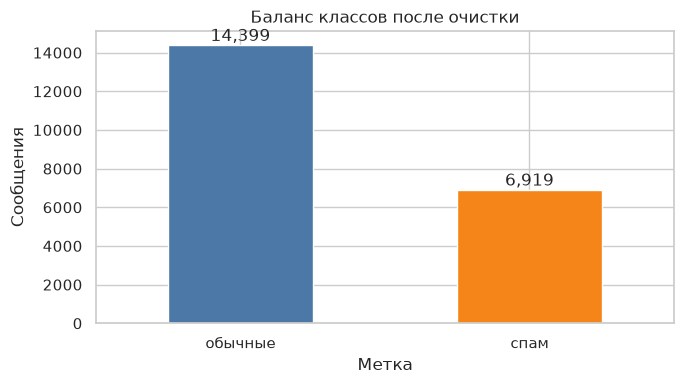

In [5]:
text_counts = text.label_name.value_counts().reindex(['обычные', 'спам'])
show_table(pd.DataFrame({'сообщений': text_counts, 'доля, %': (100*text_counts/len(text)).round(2)}), 'telegram_balance')
fig, ax = plt.subplots(figsize=(7, 4))
text_counts.plot.bar(ax=ax, color=[TEXT_COLORS[x] for x in text_counts.index], rot=0)
ax.set(title='Баланс классов после очистки', xlabel='Метка', ylabel='Сообщения')
for i, count in enumerate(text_counts):
    ax.text(i, count, f'{count:,}', ha='center', va='bottom')
finish('telegram_04_balance')

### 5. Длина сообщений: символы и слова

Слова здесь — элементы, разделённые пробелами: это простая мера длины,
а не лингвистическая токенизация. Для распределений показаны логарифмические
оси, чтобы длинные сообщения не скрыли основную массу коротких.

n_chars                                                   n_words  \
              count   mean    std   min    25%    50%    75%     max    count   
label_name                                                                      
обычные     14399.0   98.8  113.0   9.0   40.0   67.0  116.0  3942.0  14399.0   
спам         6919.0  156.0   99.1  15.0  102.0  127.0  175.0  2167.0   6919.0   

                                                      
            mean   std  min   25%   50%   75%    max  
label_name                                            
обычные     15.4  15.6  4.0   7.0  11.0  18.0  350.0  
спам        23.8  15.5  4.0  16.0  19.0  26.0  291.0

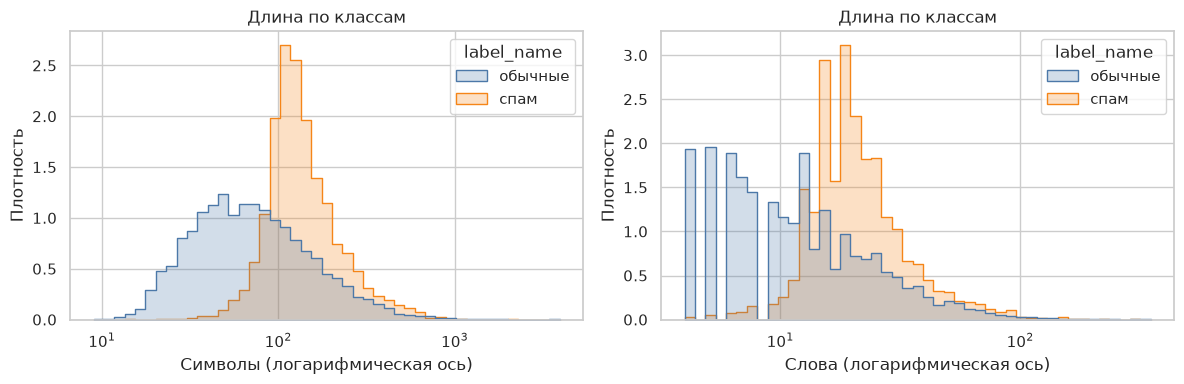

In [6]:
length_stats = text.groupby('label_name')[['n_chars', 'n_words']].describe().round(1)
show_table(length_stats, 'telegram_lengths')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, label in zip(axes, ['n_chars', 'n_words'], ['Символы', 'Слова']):
    sns.histplot(data=text, x=column, hue='label_name', palette=TEXT_COLORS,
                 bins=45, log_scale=True, stat='density', common_norm=False,
                 element='step', ax=ax)
    ax.set(xlabel=label+' (логарифмическая ось)', ylabel='Плотность', title='Длина по классам')
finish('telegram_05_lengths')

### 6. Чем отличается спам

Сравниваем доли сообщений с цифрами, ссылками, упоминаниями и восклицаниями,
долю цифр среди всех символов и долю заглавных букв **среди букв**.
Отдельно ищем целые слова free/win и русские примеры рекламной лексики.
Ссылки определяются шаблоном http(s), www или t.me; это не полный детектор URL.
Признаки описывают корреляции в этом корпусе, не являются правилами определения спама.

,есть цифры,есть ссылка,есть @упоминание,есть !
label_name,,,,
обычные,19.73,0.06,0.19,3.53
спам,82.40,0.91,12.30,42.30


digit_fraction        uppercase_fraction        n_exclamations  \
                     mean median               mean median           mean   
label_name                                                                  
обычные             0.008  0.000              0.039  0.030          0.044   
спам                0.027  0.026              0.066  0.037          0.800   

                   
           median  
label_name         
обычные       0.0  
спам          0.0

,free,win,заработок,доход,деньги,бонус,подарок,удалённо
label_name,,,,,,,,
обычные,0.01,0.16,0.00,0.00,0.15,0.00,0.01,0.04
спам,0.01,0.00,8.69,24.08,0.92,0.07,0.09,1.47


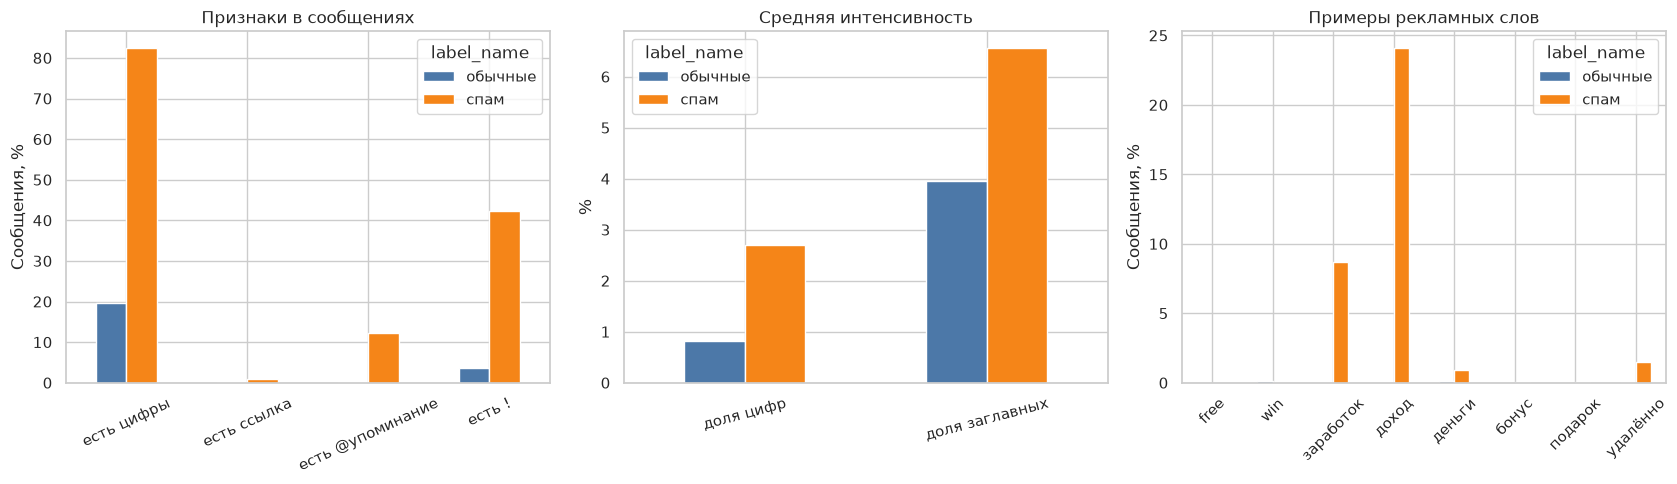

In [7]:
presence_columns = ['has_digit', 'has_url', 'has_mention', 'has_exclamation']
presence_names = {'has_digit': 'есть цифры', 'has_url': 'есть ссылка',
                  'has_mention': 'есть @упоминание', 'has_exclamation': 'есть !'}
presence_rates = (100*text.groupby('label_name')[presence_columns].mean()).rename(columns=presence_names)
show_table(presence_rates.round(2), 'telegram_feature_presence')
show_table(text.groupby('label_name')[['digit_fraction', 'uppercase_fraction', 'n_exclamations']].agg(['mean', 'median']).round(3), 'telegram_feature_intensity')
promo_rates = 100*text.groupby('label_name')[[f'word_{w}' for w in PROMO_WORDS]].mean()
promo_rates.columns = PROMO_WORDS
show_table(promo_rates.round(2), 'telegram_promotional_words')
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
presence_rates.T.plot.bar(ax=axes[0], color=[TEXT_COLORS[x] for x in presence_rates.index], rot=25)
axes[0].set(title='Признаки в сообщениях', ylabel='Сообщения, %', xlabel='')
(100*text.groupby('label_name')[['digit_fraction', 'uppercase_fraction']].mean()).T.rename(
    index={'digit_fraction': 'доля цифр', 'uppercase_fraction': 'доля заглавных'}).plot.bar(
    ax=axes[1], color=[TEXT_COLORS[x] for x in presence_rates.index], rot=15)
axes[1].set(title='Средняя интенсивность', ylabel='%', xlabel='')
promo_rates.T.plot.bar(ax=axes[2], color=[TEXT_COLORS[x] for x in promo_rates.index], rot=45)
axes[2].set(title='Примеры рекламных слов', ylabel='Сообщения, %', xlabel='')
finish('telegram_06_spam_features')

### 7. Частые слова и облака слов

Используем train, убираем URL, @имена, короткие слова и общий список русских
и английских стоп-слов. Оставляем словоформы: лемматизация не применяется.
Облако отражает частоту, а не важность слова для модели.

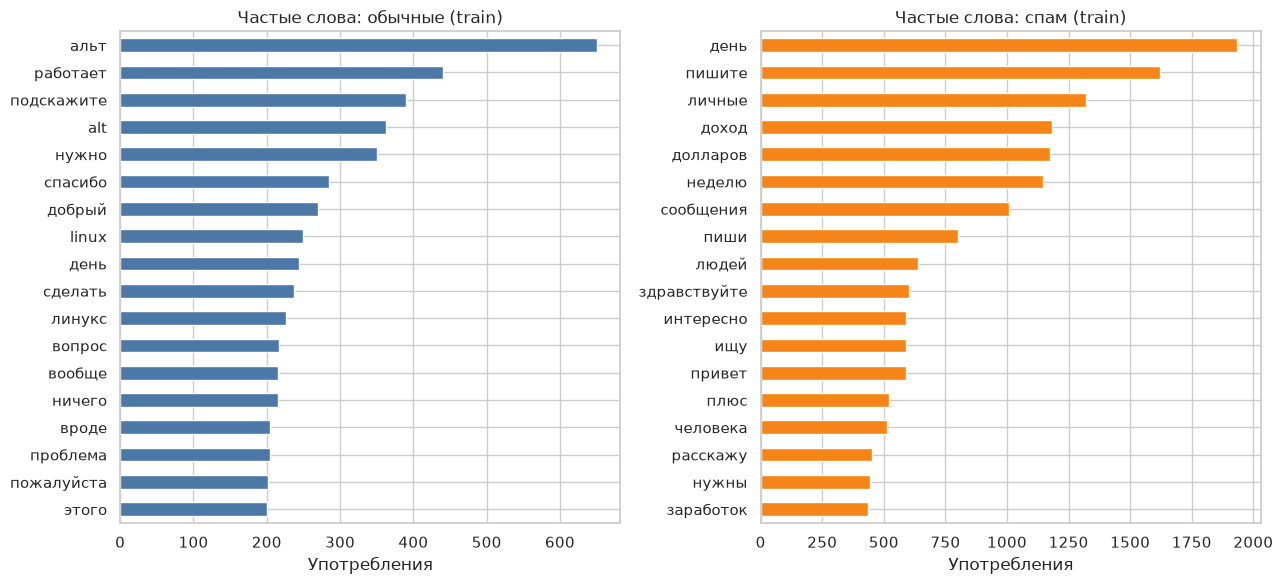

,метка,слово,частота
0,обычные,альт,650
1,обычные,работает,440
2,обычные,подскажите,390
3,обычные,alt,362
4,обычные,нужно,351
5,обычные,спасибо,285
6,обычные,добрый,270
7,обычные,linux,249
8,обычные,день,244
9,обычные,сделать,237


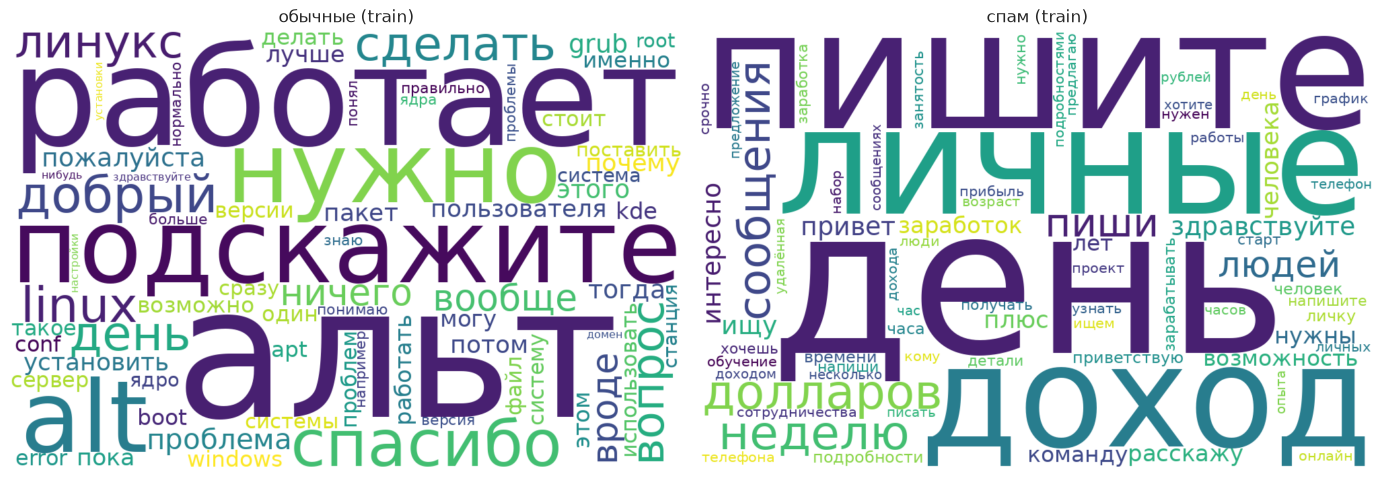

In [8]:
train_text = text[text.split.eq('train')]
frequencies = {name: Counter(word for message in train_text.loc[train_text.label_name.eq(name), 'text'] for word in tokens(message))
               for name in ['обычные', 'спам']}
word_tables = []
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, name in zip(axes, ['обычные', 'спам']):
    most_common = frequencies[name].most_common(18)
    pd.Series(dict(most_common)).sort_values().plot.barh(ax=ax, color=TEXT_COLORS[name])
    ax.set(title=f'Частые слова: {name} (train)', xlabel='Употребления')
    word_tables.extend({'метка': name, 'слово': w, 'частота': n} for w, n in most_common)
finish('telegram_07_top_words')
show_table(pd.DataFrame(word_tables), 'telegram_top_words')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
font_path = font_manager.findfont('DejaVu Sans')
for ax, name in zip(axes, ['обычные', 'спам']):
    cloud = WordCloud(font_path=font_path, width=1000, height=650, background_color='white',
                      max_words=70, collocations=False, random_state=SEED).generate_from_frequencies(frequencies[name])
    ax.imshow(cloud, interpolation='bilinear')
    ax.set_title(name+' (train)')
    ax.axis('off')
finish('telegram_07_wordclouds')

### 8. Картинка данных: тексты на плоскости

Текст превращаем в TF-IDF по словам и биграммам, сокращаем до 50 измерений SVD,
затем до двух через t-SNE. TF-IDF и SVD обучены только на train.
Для графика взято до 3 000 сообщений train с сохранением пропорции меток.
Цвет показывает класс; близкие точки имеют похожие признаки текста.
Оси t-SNE не имеют самостоятельного смысла, видимые кластеры не доказывают
качество будущей модели и могут отражать тему Linux против рекламы.

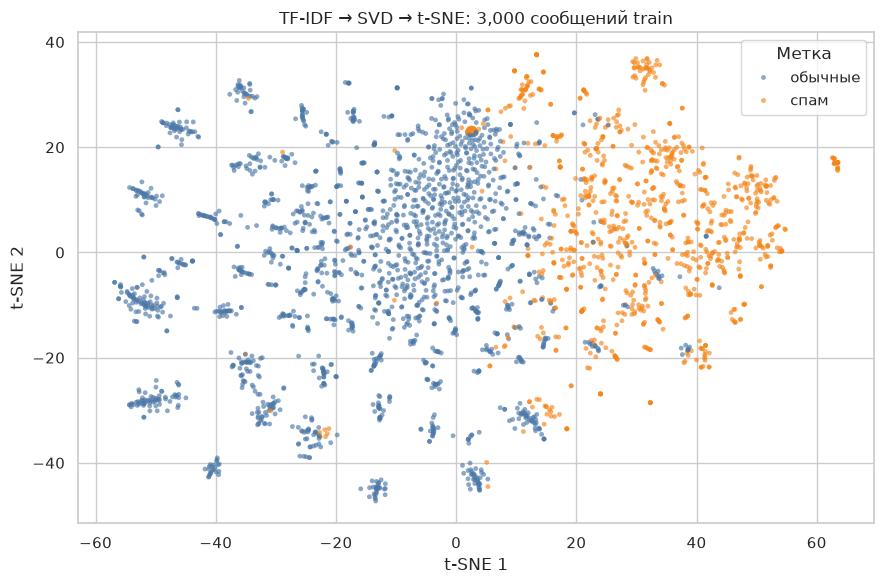

TF-IDF: (14922, 23312) | доля объяснённой дисперсии SVD: 0.082


In [9]:
plot_text = stratified_sample(train_text, 'label', 3000, SEED)
with threadpool_limits(limits=2):
    tfidf = TfidfVectorizer(tokenizer=tokens, token_pattern=None, lowercase=False,
                            ngram_range=(1, 2), min_df=2, max_df=.98, max_features=30000,
                            dtype=np.float32)
    train_matrix = tfidf.fit_transform(train_text.text)
    svd = TruncatedSVD(n_components=50, random_state=SEED)
    svd.fit(train_matrix)
    text_vectors = svd.transform(tfidf.transform(plot_text.text))
    text_xy = TSNE(n_components=2, perplexity=35, init='pca', learning_rate='auto',
                   max_iter=750, random_state=SEED, n_jobs=2).fit_transform(text_vectors)
text_projection = plot_text[['sample_id', 'label', 'label_name']].copy()
text_projection[['x', 'y']] = text_xy
text_projection.to_parquet(TABLES/'telegram_projection.parquet', index=False)
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=text_projection.sample(frac=1, random_state=SEED), x='x', y='y',
                hue='label_name', palette=TEXT_COLORS, s=12, alpha=.65, linewidth=0, ax=ax)
ax.set(title=f'TF-IDF → SVD → t-SNE: {len(plot_text):,} сообщений train', xlabel='t-SNE 1', ylabel='t-SNE 2')
ax.legend(title='Метка')
finish('telegram_08_projection')
print('TF-IDF:', train_matrix.shape, '| доля объяснённой дисперсии SVD:', round(svd.explained_variance_ratio_.sum(), 3))

На проекции заметны области, где преобладает спам, и области обычных сообщений,
но встречаются смешанные точки. Это согласуется с различием лексики и тем в облаках
слов; для оценки обобщения потребуется независимая проверка модели, особенно
на обычных сообщениях вне Linux-тематики.

### 9. Выводы: что важно для обогащения текста

In [10]:
medians = text.groupby('label_name')[['n_chars', 'n_words']].median()
url_percent = (100*text.groupby('label_name').has_url.mean()).round(1)
uppercase_percent = (100*text.groupby('label_name').uppercase_fraction.mean()).round(1)
conclusion_text = (
    f'После очистки осталось **{len(text):,} сообщений**; спам — **{100*text.label.mean():.1f}%**. '
    f'Удалено **{len(removed)}** повторов после нормализации. '
    f'Медианная длина обычных сообщений — **{medians.loc["обычные", "n_chars"]:.0f}** символов, '
    f'спама — **{medians.loc["спам", "n_chars"]:.0f}**. '
    f'Ссылки есть в **{url_percent["обычные"]}%** обычных сообщений и **{url_percent["спам"]}%** спама. '
    f'Средняя доля заглавных букв: **{uppercase_percent["обычные"]}% / {uppercase_percent["спам"]}%** соответственно.'
)
display(Markdown(conclusion_text))
display(Markdown(
    f'Цифры есть в **{presence_rates.loc["обычные", "есть цифры"]:.1f}% / '
    f'{presence_rates.loc["спам", "есть цифры"]:.1f}%** сообщений, '
    f'восклицания — в **{presence_rates.loc["обычные", "есть !"]:.1f}% / '
    f'{presence_rates.loc["спам", "есть !"]:.1f}%** (обычные / спам). '
    f'Английские free и win встречаются редко; здесь полезнее проверить русскую лексику: '
    f'слово «доход» есть в **{promo_rates.loc["спам", "доход"]:.1f}%** спама. '
    'Наличие ссылки само по себе покрывает лишь небольшую часть спама.'
))
display(Markdown("""
**Для обогащения:** добавлять короткий и длинный спам, сообщения без ссылок,
обычные сообщения со ссылками и рекламными словами; сохранять разнообразие тем.
Обычная часть связана с Linux, поэтому полезны обычные сообщения из других тематик,
чтобы модель не подменяла «спам» признаком «текст не про Linux».
Частые слова и облака использовать для проверки покрытия тем, а не как готовый фильтр.
Синонимизация и генерация не должны менять метку; вариации одного шаблона остаются
в тренировочной группе вместе с исходным текстом.
Для сравнения вариантов обогащения важны macro-F1 и показатели класса spam;
все параметры выбирать по train/val при фиксированном test.
"""))

После очистки осталось **21,318 сообщений**; спам — **32.5%**. Удалено **93** повторов после нормализации. Медианная длина обычных сообщений — **67** символов, спама — **127**. Ссылки есть в **0.1%** обычных сообщений и **0.9%** спама. Средняя доля заглавных букв: **3.9% / 6.6%** соответственно.

Цифры есть в **19.7% / 82.4%** сообщений, восклицания — в **3.5% / 42.3%** (обычные / спам). Английские free и win встречаются редко; здесь полезнее проверить русскую лексику: слово «доход» есть в **24.1%** спама. Наличие ссылки само по себе покрывает лишь небольшую часть спама.


**Для обогащения:** добавлять короткий и длинный спам, сообщения без ссылок,
обычные сообщения со ссылками и рекламными словами; сохранять разнообразие тем.
Обычная часть связана с Linux, поэтому полезны обычные сообщения из других тематик,
чтобы модель не подменяла «спам» признаком «текст не про Linux».
Частые слова и облака использовать для проверки покрытия тем, а не как готовый фильтр.
Синонимизация и генерация не должны менять метку; вариации одного шаблона остаются
в тренировочной группе вместе с исходным текстом.
Для сравнения вариантов обогащения важны macro-F1 и показатели класса spam;
все параметры выбирать по train/val при фиксированном test.


## Датасет 2. Caltech: рамки животных

### 1. Загрузка кадров и файлов разметки

Читаем полный каталог 140 камер, готовый manifest и выбранную разметку COCO.
JPG загружаем по путям manifest, а не по всем файлам папки с кэшем.
Разметка исходного датасета содержала виды; для нашей задачи все животные — `animal`.

In [11]:
source_images = load_caltech_source(ROOT)
manifest = pd.read_parquet(DATA/'caltech_manifest.parquet')
checks = pd.read_parquet(DATA/'caltech_image_checks.parquet')
assert set(manifest.image_id) == set(checks.image_id)
images = manifest.merge(checks, on='image_id', validate='one_to_one')
images['presence'] = images.has_animal.map(IMAGE_NAMES)
coco = json.loads((DATA/'caltech_annotations.json').read_text())
eligible = pd.read_parquet(DATA/'caltech_eligible.parquet')
source20 = source_images[source_images.location.isin(images.location.unique())].copy()
print('Источник:', source_images.shape, '| manifest:', manifest.shape)
print('COCO ключи:', list(coco), '| категории:', coco['categories'])
print('Пример изображения:', {k: coco['images'][0][k] for k in ['id', 'file_name', 'width', 'height', 'location']})
print('Пример рамки:', coco['annotations'][0])

Источник: (243100, 12) | manifest: (4000, 18)
COCO ключи: ['info', 'licenses', 'categories', 'images', 'annotations'] | категории: [{'id': 1, 'name': 'animal'}]
Пример изображения: {'id': '59ec537a-23d2-11e8-a6a3-ec086b02610b', 'file_name': '59ec537a-23d2-11e8-a6a3-ec086b02610b.jpg', 'width': 2048, 'height': 1494, 'location': '61'}
Пример рамки: {'id': 1, 'image_id': '59641ec1-23d2-11e8-a6a3-ec086b02610b', 'category_id': 1, 'bbox': [2112.0, 777.6, 448.0, 515.1999999999999], 'area': 230809.59999999998, 'iscrowd': 0}


### 2. Сколько кадров и камер, как устроена разметка

В COCO у рамки есть image_id, category_id=1, bbox=[x,y,width,height], area и iscrowd.
Отрицательные кадры есть в images, но не имеют записей в annotations.
В YOLO индекс animal равен 0, координаты нормированы, отрицательный TXT пустой.

In [12]:
show_table(pd.DataFrame([
    {'этап': 'полный каталог', 'кадров': len(source_images), 'камер': source_images.location.nunique()},
    {'этап': 'исходные кадры выбранных камер', 'кадров': len(source20), 'камер': source20.location.nunique()},
    {'этап': 'прошли фильтры разметки', 'кадров': len(eligible), 'камер': eligible.location.nunique()},
    {'этап': 'рабочая выборка', 'кадров': len(images), 'камер': images.location.nunique()},
]), 'caltech_data_stages')
print('Рамок animal:', len(coco['annotations']), '| отсутствующих JPG:', sum(not (ROOT/p).is_file() for p in images.local_path))
show_table(images[['image_id', 'location', 'split', 'has_animal', 'n_boxes', 'bbox_json']].head(), 'caltech_schema_example')
print('Фильтры до отбора:', summary['caltech']['filter_exclusions'])

,этап,кадров,камер
0,полный каталог,243100,140
1,исходные кадры выбранных камер,56468,20
2,прошли фильтры разметки,48786,20
3,рабочая выборка,4000,20


Рамок animal: 2068 | отсутствующих JPG: 0


,image_id,location,split,has_animal,n_boxes,bbox_json
0,59641e29-23d2-11e8-a6a3-ec086b02610b,0,val,False,0,[]
1,59641ec1-23d2-11e8-a6a3-ec086b02610b,0,val,True,1,"[{""category_id"": 1, ""bbox"": [2112.0, 777.6, 44..."
2,59641ec3-23d2-11e8-a6a3-ec086b02610b,0,val,False,0,[]
3,59641eca-23d2-11e8-a6a3-ec086b02610b,0,val,True,1,"[{""category_id"": 1, ""bbox"": [67.2, 998.4000000..."
4,59642041-23d2-11e8-a6a3-ec086b02610b,0,val,True,1,"[{""category_id"": 1, ""bbox"": [1070.08, 593.92, ..."


Фильтры до отбора: {'animal_without_complete_valid_boxes': 7682}


### 3. С животными и без: исходный дисбаланс и 50/50 после отбора

«Пустой» означает **без животных**, а не обязательно без людей и машин.
Баланс исходных данных и искусственно сбалансированной выборки показан отдельно.
Наличие животного — состав выборки, а не отдельная задача классификации вместо рамок.

,с животными,без животных,неизвестная метка,"доля животных, %"
этап,,,,
полный каталог,112638,130462,0,46.33
выбранные камеры до фильтров,49996,6472,0,88.54
готовые 4000 кадров,2000,2000,0,50.00


,без животных,с животными
split,,
train,1000,1000
val,500,500
test,500,500


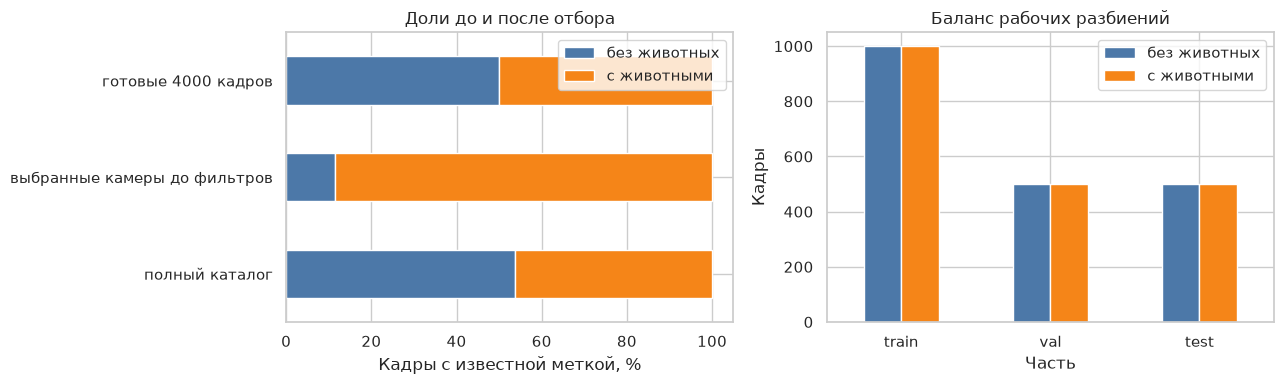

In [13]:
balance_rows = []
for name, frame in [('полный каталог', source_images), ('выбранные камеры до фильтров', source20), ('готовые 4000 кадров', images)]:
    known = frame.has_animal.dropna().astype(bool)
    balance_rows.append({'этап': name, 'с животными': int(known.sum()), 'без животных': int((~known).sum()),
                         'неизвестная метка': int(frame.has_animal.isna().sum()), 'доля животных, %': round(100*known.mean(), 2)})
show_table(pd.DataFrame(balance_rows).set_index('этап'), 'caltech_balance_stages')
split_balance = pd.crosstab(images.split, images.has_animal).reindex(['train', 'val', 'test'])
split_balance.columns = ['без животных', 'с животными']
show_table(split_balance, 'caltech_split_balance')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.DataFrame(balance_rows).set_index('этап')[['без животных', 'с животными']].div(
    pd.DataFrame(balance_rows).set_index('этап')[['без животных', 'с животными']].sum(axis=1), axis=0
).mul(100).plot.barh(stacked=True, ax=axes[0], color=list(IMAGE_COLORS.values()))
axes[0].set(title='Доли до и после отбора', xlabel='Кадры с известной меткой, %', ylabel='')
split_balance.plot.bar(ax=axes[1], color=list(IMAGE_COLORS.values()), rot=0)
axes[1].set(title='Баланс рабочих разбиений', xlabel='Часть', ylabel='Кадры')
finish('caltech_03_balance')

### 4. По камерам: количество, доля пустых и выбор камер

Для выбора камер смотрим **исходные доли**, доступность рамок и независимых отрицательных
серий. В готовой выборке каждая камера уже 50/50, это не её природная частота животных.
Выбраны 20 официальных ECCV-камер с разметкой животных; остальные 120 также есть
в таблице исходного каталога, но их JPG не скачиваются.

,исходных_кадров,доля_животных,кадров_с_рамками,доля_без_животных,выбрано,split
location,,,,,,
96,37766,0.029,0,0.971,0,NaN
26,28670,0.024,24,0.976,0,NaN
76,13979,0.267,0,0.733,0,NaN
114,13157,0.4,0,0.6,0,NaN
57,12805,0.338,481,0.662,0,NaN
23,12375,0.169,242,0.831,0,NaN
106,11089,0.164,0,0.836,0,NaN
70,10946,0.26,382,0.74,0,NaN
38,9742,0.98,8617,0.02,156,train


,исходных_кадров,доля_животных,кадров_с_рамками,доля_без_животных,выбрано,split
location,,,,,,
0,1784,0.378,662,0.622,624,val
7,1837,0.898,1360,0.102,154,test
28,1271,0.893,886,0.107,124,test
33,3928,0.913,2891,0.087,258,train
38,9742,0.98,8617,0.02,156,train
40,1060,0.896,780,0.104,86,val
43,4058,0.864,2744,0.136,382,train
46,6035,0.884,4074,0.116,492,test
51,1489,0.778,950,0.222,252,train


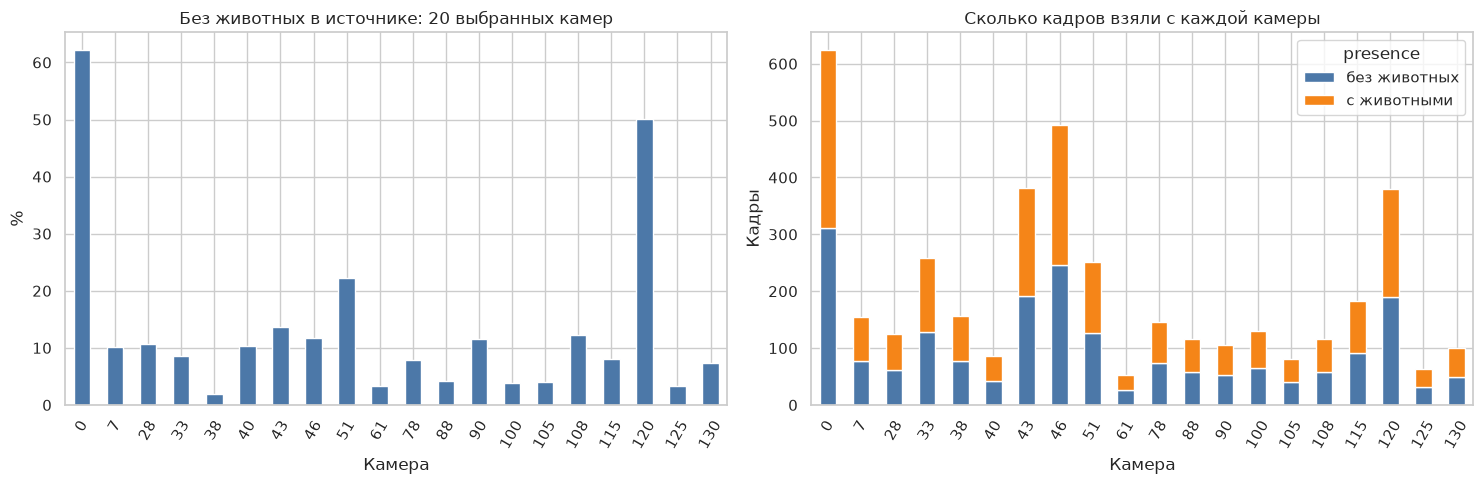

In [14]:
camera_source = source_images.groupby('location').agg(
    исходных_кадров=('image_id', 'size'), доля_животных=('has_animal', 'mean'),
    кадров_с_рамками=('source_animal_boxes', lambda s: int(s.gt(0).sum())))
camera_source['доля_без_животных'] = 1-camera_source['доля_животных']
camera_source['выбрано'] = images.groupby('location').size().reindex(camera_source.index, fill_value=0)
camera_source['split'] = images.groupby('location').split.first().reindex(camera_source.index)
show_table(camera_source.sort_values('исходных_кадров', ascending=False).head(20).round(3), 'caltech_top_source_cameras')
camera_source.to_parquet(TABLES/'caltech_all_140_cameras.parquet')
selected_cameras = sorted(images.location.unique(), key=int)
chosen_camera_table = camera_source.loc[selected_cameras].copy()
show_table(chosen_camera_table.round(3), 'caltech_selected_cameras')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
(100*chosen_camera_table['доля_без_животных']).plot.bar(ax=axes[0], color='#4c78a8', rot=60)
axes[0].set(title='Без животных в источнике: 20 выбранных камер', xlabel='Камера', ylabel='%')
camera_balance = pd.crosstab(images.location, images.presence).reindex(selected_cameras)[['без животных', 'с животными']]
camera_balance.plot.bar(stacked=True, ax=axes[1], color=list(IMAGE_COLORS.values()), rot=60)
axes[1].set(title='Сколько кадров взяли с каждой камеры', xlabel='Камера', ylabel='Кадры')
finish('caltech_04_cameras')

### 5. Серии кадров и одинаковые изображения

Смотрим число кадров при одном срабатывании и интервалы между ними в источнике.
В рабочей выборке оставлен один кадр на серию. Точные копии ищем по SHA-256;
совпадения dHash считаем только кандидатами, поскольку неподвижный фон и маленькое
животное могут давать одинаковый грубый хеш. Ничего не удаляем по dHash автоматически.

,серий
кадров,
1,5272
2,1206
3,15916
4,24
5,188


Серий: 22606 | серий с >1 кадром: 17334 | медианный интервал внутри серии, с: 1.0
Максимум кадров из одной серии в рабочей выборке: 1


,image_id,location,seq_id,split,has_animal
1203,58823baa-23d2-11e8-a6a3-ec086b02610b,120,70100d1c-5567-11e8-bc0b-dca9047ef277,train,True
1466,59310064-23d2-11e8-a6a3-ec086b02610b,120,70100ccc-5567-11e8-9115-dca9047ef277,train,True


Лишних точных копий: 1 | лишних совпадений dHash: 475
Точных копий между разбиениями: 0


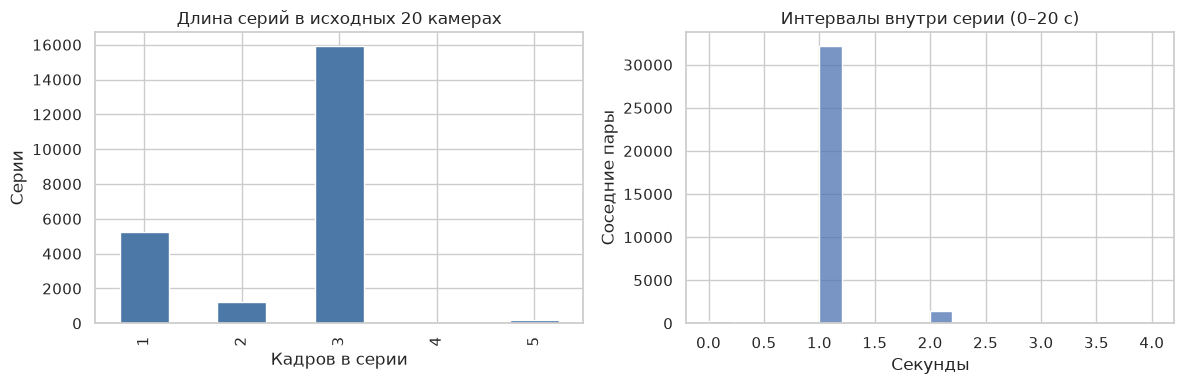

In [15]:
series = source20.groupby(['location', 'seq_id']).agg(кадров=('image_id', 'size'),
                                                     заявлено_кадров=('seq_num_frames', 'max'))
show_table(series['кадров'].value_counts().sort_index().to_frame('серий'), 'caltech_series_lengths')
ordered_source = source20.assign(time=pd.to_datetime(source20.date_captured, errors='coerce')).sort_values(['location', 'seq_id', 'time'])
intervals = ordered_source.groupby(['location', 'seq_id']).time.diff().dt.total_seconds().dropna()
print('Серий:', len(series), '| серий с >1 кадром:', int(series['кадров'].gt(1).sum()),
      '| медианный интервал внутри серии, с:', intervals.median())
print('Максимум кадров из одной серии в рабочей выборке:', images.groupby('seq_id').size().max())
exact_candidates = images[images.duplicated('sha256', keep=False)].sort_values('sha256')
exact_candidates[['image_id', 'location', 'seq_id', 'split', 'has_animal', 'sha256']].to_parquet(TABLES/'caltech_exact_duplicate_candidates.parquet', index=False)
show_table(exact_candidates[['image_id', 'location', 'seq_id', 'split', 'has_animal']])
print('Лишних точных копий:', int(images.duplicated('sha256').sum()),
      '| лишних совпадений dHash:', int(images.duplicated('dhash').sum()))
print('Точных копий между разбиениями:', int(images.groupby('sha256').split.nunique().gt(1).sum()))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
series['кадров'].value_counts().sort_index().plot.bar(ax=axes[0], color='#4c78a8')
axes[0].set(title='Длина серий в исходных 20 камерах', xlabel='Кадров в серии', ylabel='Серии')
sns.histplot(intervals[intervals.between(0, 20)], bins=20, ax=axes[1])
axes[1].set(title='Интервалы внутри серии (0–20 с)', xlabel='Секунды', ylabel='Соседние пары')
finish('caltech_05_sequences')

### 6. День и ночь: сколько чёрно-белых кадров

Почти чёрно-белый кадр: не менее 95% пикселей имеют разброс RGB ≤5 на копии 64×64.
Это **приближение режима камеры**, не подтверждённая метка ночи: серый кадр бывает
днём, а тёмный цветной — ночью. Дополнительно смотрим время из метаданных камеры.

,цветные,почти ч/б
presence,,
без животных,1487,513
с животными,835,1165


,цветные,почти ч/б
presence,,
без животных,74.35,25.65
с животными,41.75,58.25


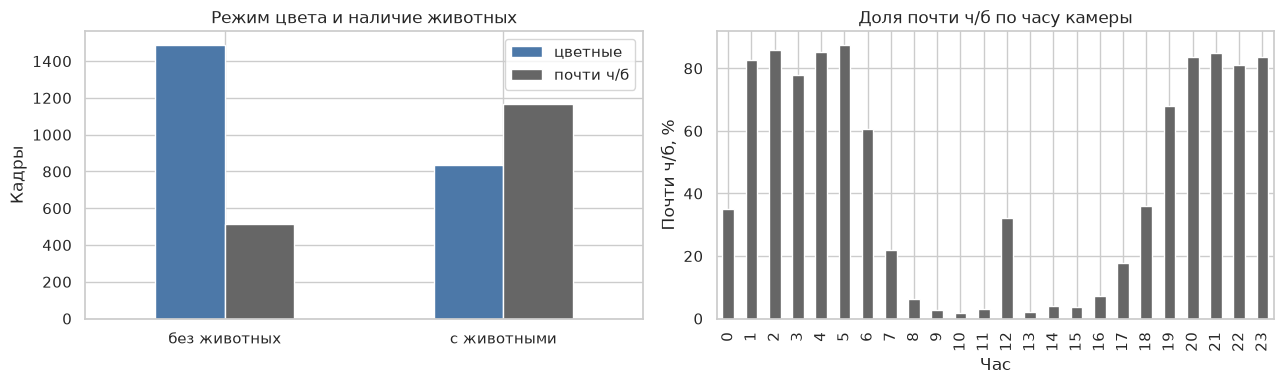

In [16]:
images['is_monochrome'] = images.grayscale_fraction.ge(.95)
images['capture_hour'] = pd.to_datetime(images.date_captured, errors='coerce').dt.hour
mono_counts = pd.crosstab(images.presence, images.is_monochrome).reindex(columns=[False, True], fill_value=0)
mono_counts.columns = ['цветные', 'почти ч/б']
show_table(mono_counts, 'caltech_monochrome_counts')
show_table((mono_counts.div(mono_counts.sum(axis=1), axis=0)*100).round(2), 'caltech_monochrome_percent')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mono_counts.plot.bar(ax=axes[0], color=['#4c78a8', '#666666'], rot=0)
axes[0].set(title='Режим цвета и наличие животных', xlabel='', ylabel='Кадры')
by_hour = images.groupby('capture_hour').is_monochrome.agg(['mean', 'size'])
(100*by_hour['mean']).plot.bar(ax=axes[1], color='#666666')
axes[1].set(title='Доля почти ч/б по часу камеры', xlabel='Час', ylabel='Почти ч/б, %')
finish('caltech_06_monochrome')

### 7. Качество фото: размер, яркость, размытость

Все JPG проверены на чтение и соответствие размерам метаданных. Для резкости считаем
дисперсию лапласиана на копии с длинной стороной до 256 px. Нижние 5% — кандидаты
на размытие, а не подтверждённый брак: тёмная сцена и ровный фон тоже дают низкую оценку.
Тёмный кандидат: средняя яркость <35 из 255 и более 80% пикселей <30.
Исходные изображения не изменяются. Кандидатов сохраняем для ручного просмотра.

,actual_width,actual_height,size_bytes,brightness,contrast,laplacian_variance,dark_pixel_fraction
count,4000.00,4000.00,4000.00,4000.00,4000.00,4000.00,4000.00
mean,2090.24,1536.22,407157.22,87.20,43.98,1274.09,0.21
std,140.88,116.15,155575.42,37.73,20.12,1199.17,0.21
min,2048.00,1494.00,93814.00,3.34,7.12,261.98,0.00
25%,2048.00,1494.00,327733.25,54.58,26.07,435.09,0.03
50%,2048.00,1494.00,368320.50,82.89,43.68,710.54,0.12
75%,2048.00,1536.00,503580.50,122.58,59.37,1786.73,0.32
max,2560.00,1920.00,1336496.00,206.94,103.81,10453.91,0.99


,blur_candidate,dark_candidate
presence,,
без животных,2.9,1.0
с животными,7.1,0.7


Порог нижних 5% резкости: 336.03 | повреждённых файлов: 0


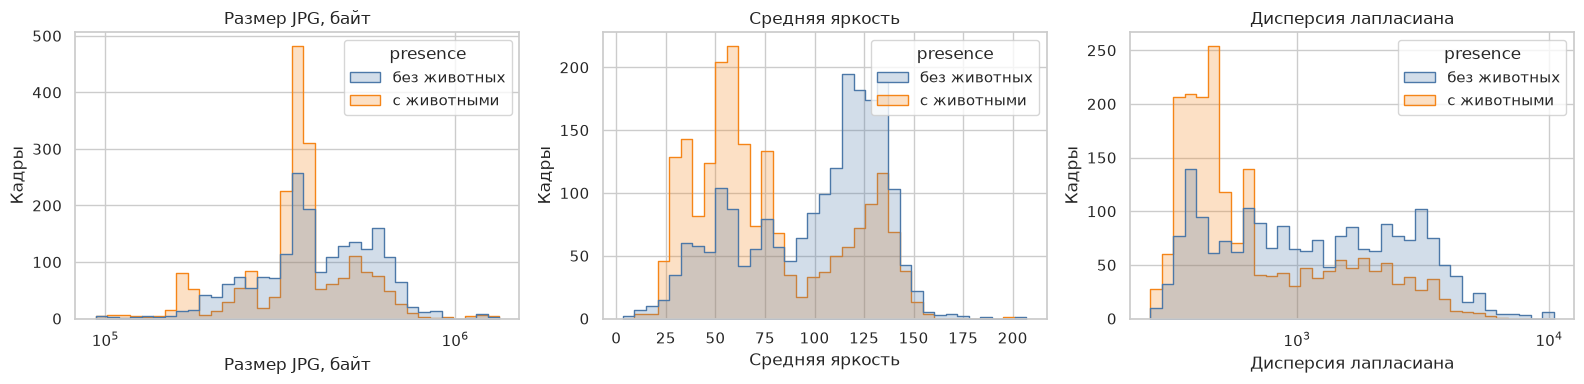

In [17]:
quality, image_vectors, vector_ids = image_feature_cache(ROOT, manifest, checks)
images = images.merge(quality, on='image_id', validate='one_to_one')
blur_threshold = float(images.laplacian_variance.quantile(.05))
images['blur_candidate'] = images.laplacian_variance.le(blur_threshold)
images['dark_candidate'] = images.brightness.lt(35) & images.dark_pixel_fraction.gt(.80)
show_table(images[['actual_width', 'actual_height', 'size_bytes', 'brightness', 'contrast',
                   'laplacian_variance', 'dark_pixel_fraction']].describe().round(2), 'caltech_quality_stats')
show_table((100*images.groupby('presence')[['blur_candidate', 'dark_candidate']].mean()).round(2), 'caltech_quality_flags_percent')
print('Порог нижних 5% резкости:', round(blur_threshold, 2), '| повреждённых файлов:', int(images.status.ne('ok').sum()))
images[['image_id', 'location', 'presence', 'brightness', 'laplacian_variance', 'blur_candidate',
        'dark_candidate']].to_parquet(TABLES/'caltech_quality_candidates.parquet', index=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, feature, title in zip(axes, ['size_bytes', 'brightness', 'laplacian_variance'],
                             ['Размер JPG, байт', 'Средняя яркость', 'Дисперсия лапласиана']):
    sns.histplot(data=images, x=feature, hue='presence', palette=IMAGE_COLORS,
                 bins=35, element='step', log_scale=feature!='brightness', ax=ax)
    ax.set(title=title, xlabel=title, ylabel='Кадры')
finish('caltech_07_quality')

### 8. Рамки: количество, размер, положение и ошибки

Проверяем положительную ширину/высоту, конечные числа, границы изображения,
единственную метку animal и отсутствие рамок у отрицательных кадров.
Для исходной версии рамок отдельно показываем дефекты **до фильтрации**;
геометрически корректная рамка ещё не гарантирует правильную семантическую разметку.

,количество
всего исходных рамок животных,62369
нет размеров исходного кадра,0
нечисловая / неположительная геометрия,0
"выходит за границы, включая округление",464
выходит за границы более чем на 1px,0


,количество
рамок в рабочей выборке,2068
некорректных рабочих рамок,0
рамок у отрицательных кадров,0
рамок с неверной меткой,0


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,520.0,0.0722,0.1645,0.0015,0.0165,0.0250,0.0467,0.9883
train,1029.0,0.0511,0.0875,0.0015,0.0161,0.0280,0.0502,0.9344
val,519.0,0.0607,0.1039,0.0009,0.0192,0.0337,0.0598,0.9931


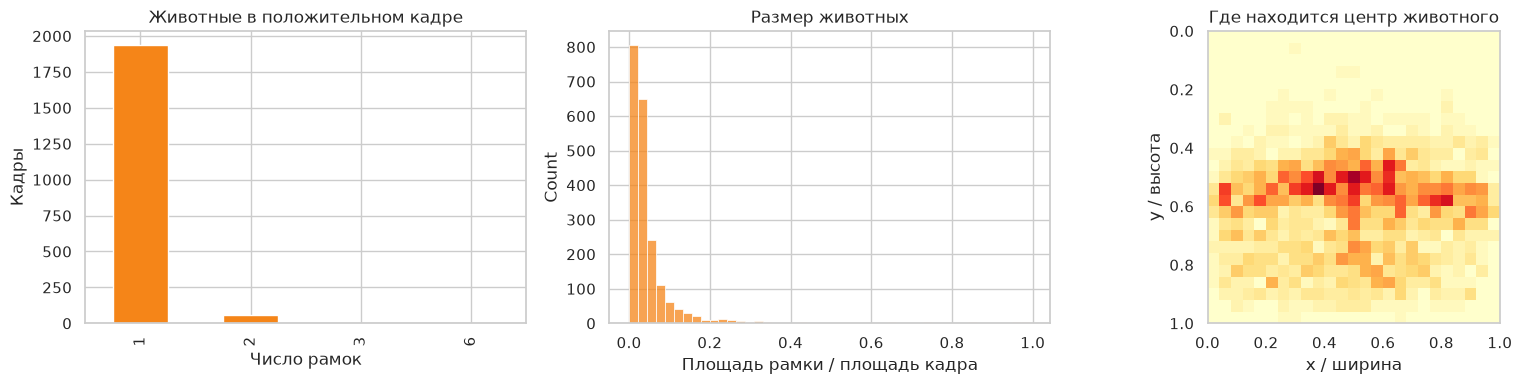

In [18]:
box_rows = []
for row in images.itertuples():
    for box in json.loads(row.bbox_json):
        x, y, w, h = box['bbox']
        invalid_box = (not np.isfinite([x, y, w, h]).all() or w<=0 or h<=0 or x<0 or y<0 or x+w>row.width+1e-6 or y+h>row.height+1e-6)
        box_rows.append({'image_id': row.image_id, 'split': row.split, 'category_id': box['category_id'],
                         'area_fraction': w*h/(row.width*row.height), 'cx': (x+w/2)/row.width,
                         'cy': (y+h/2)/row.height, 'invalid': invalid_box})
box_stats = pd.DataFrame(box_rows)
box_stats.to_parquet(TABLES/'caltech_box_statistics.parquet', index=False)
source_boxes = json.loads((ROOT/'data/raw/caltech_bboxes_20200316.json').read_text())
source_sizes = {str(i['id']): (i['width'], i['height']) for i in source_boxes['images']}
raw_box_audit = Counter({key: 0 for key in [
    'всего исходных рамок животных', 'нет размеров исходного кадра',
    'нечисловая / неположительная геометрия',
    'выходит за границы, включая округление', 'выходит за границы более чем на 1px']})
for box in source_boxes['annotations']:
    if not box.get('bbox') or int(box['category_id']) in {30, 33}:
        continue
    raw_box_audit['всего исходных рамок животных'] += 1
    x, y, w, h = box['bbox']
    dims = source_sizes.get(str(box['image_id']))
    if not dims:
        raw_box_audit['нет размеров исходного кадра'] += 1
    elif not np.isfinite([x,y,w,h]).all() or w<=0 or h<=0:
        raw_box_audit['нечисловая / неположительная геометрия'] += 1
    elif x<0 or y<0 or x+w>dims[0] or y+h>dims[1]:
        raw_box_audit['выходит за границы, включая округление'] += 1
        if x < -1 or y < -1 or x+w > dims[0]+1 or y+h > dims[1]+1:
            raw_box_audit['выходит за границы более чем на 1px'] += 1
show_table(pd.Series(raw_box_audit, name='количество').to_frame(), 'caltech_source_box_audit')
show_table(pd.Series({'рамок в рабочей выборке': len(box_stats), 'некорректных рабочих рамок': int(box_stats.invalid.sum()),
                      'рамок у отрицательных кадров': int(images.loc[~images.has_animal, 'n_boxes'].sum()),
                      'рамок с неверной меткой': int(box_stats.category_id.ne(1).sum())}, name='количество').to_frame(), 'caltech_selected_box_audit')
show_table(box_stats.groupby('split').area_fraction.describe().round(4), 'caltech_box_sizes')
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
images.loc[images.has_animal, 'n_boxes'].value_counts().sort_index().plot.bar(ax=axes[0], color='#f58518')
axes[0].set(title='Животные в положительном кадре', xlabel='Число рамок', ylabel='Кадры')
sns.histplot(data=box_stats, x='area_fraction', bins=45, ax=axes[1], color='#f58518')
axes[1].set(title='Размер животных', xlabel='Площадь рамки / площадь кадра')
axes[2].hist2d(box_stats.cx, box_stats.cy, bins=25, range=[[0,1],[0,1]], cmap='YlOrRd')
axes[2].invert_yaxis()
axes[2].set(title='Где находится центр животного', xlabel='x / ширина', ylabel='y / высота', aspect='equal')
finish('caltech_08_boxes')

### 9. Примеры: сетка кадров с рамками

Сначала пары «без животных / с животными» для одних и тех же камер.
Затем кандидаты на проблемы качества. Это выборочная проверка, не просмотр всех кадров.

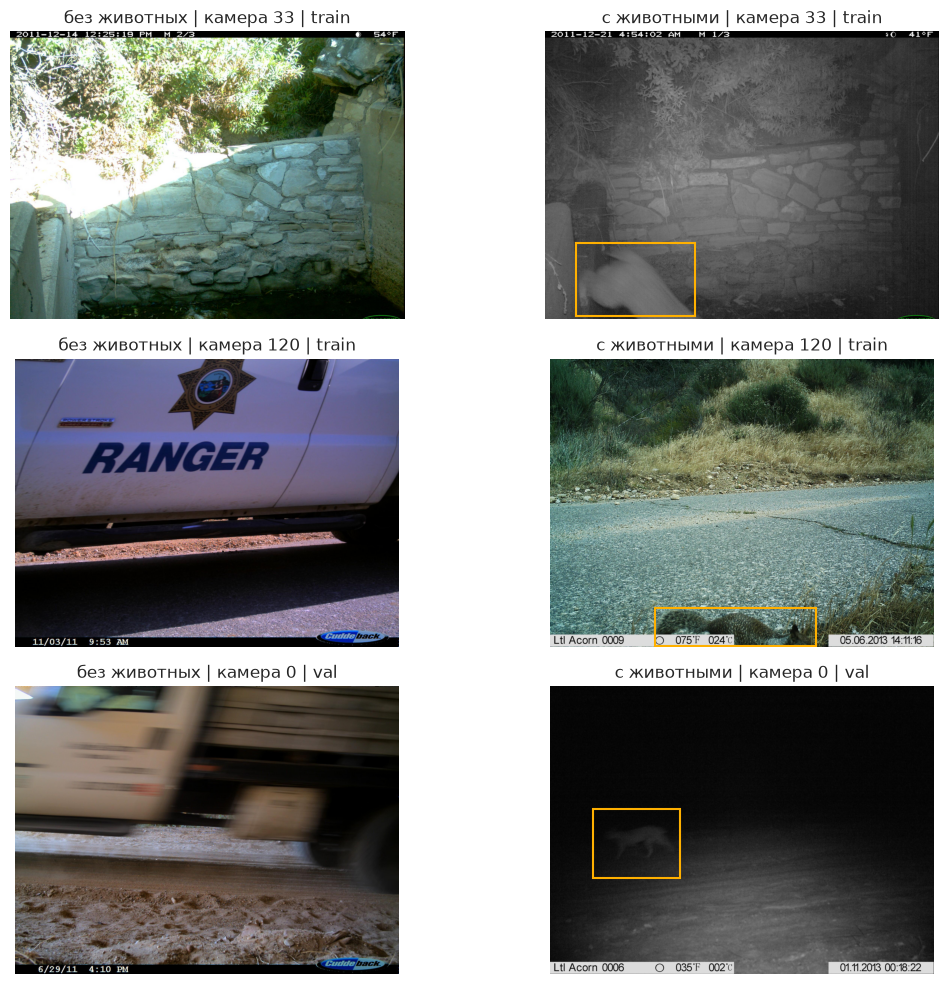

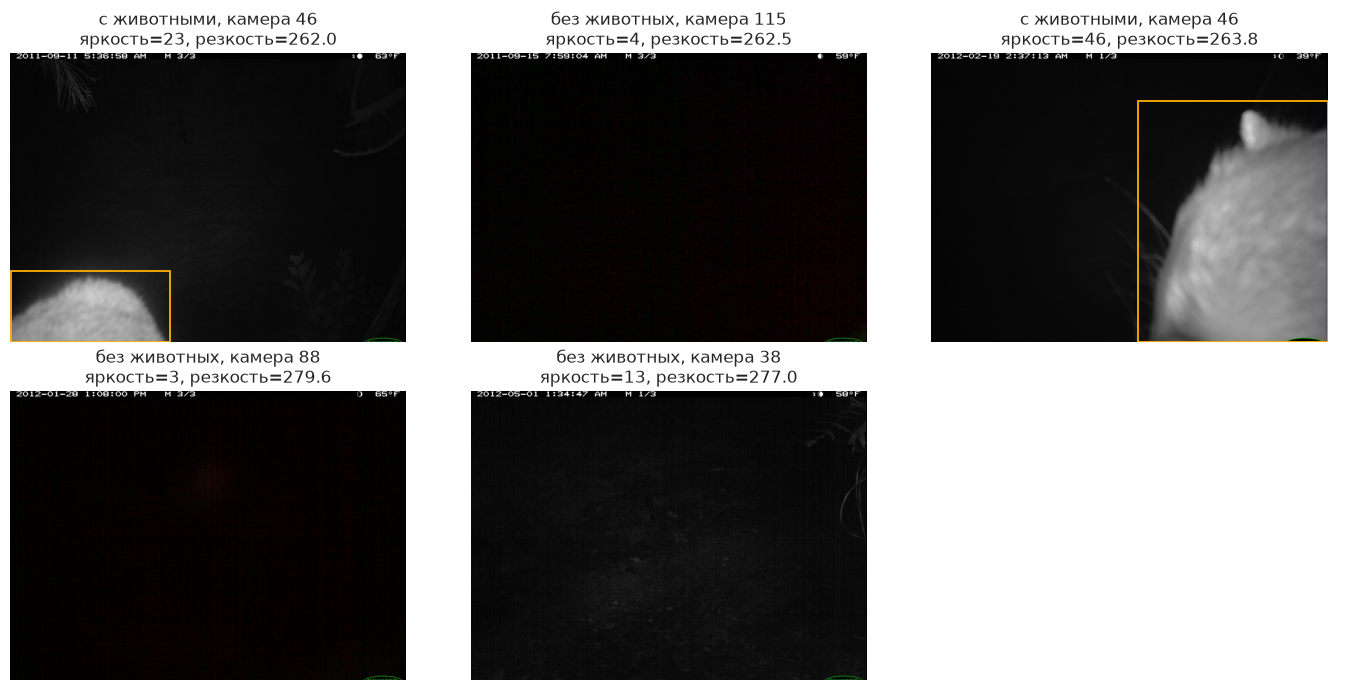

In [19]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for camera_idx, camera in enumerate(['33', '120', '0']):
    for col, positive in enumerate([False, True]):
        row = images[(images.location==camera) & (images.has_animal==positive)].sample(n=1, random_state=SEED).iloc[0]
        ax = axes[camera_idx, col]
        with Image.open(ROOT/row.local_path) as image:
            ax.imshow(image)
        for box in json.loads(row.bbox_json):
            x,y,w,h = box['bbox']
            ax.add_patch(Rectangle((x,y),w,h,fill=False,edgecolor='#ffb000',linewidth=1.5))
        ax.set_title(f'{row.presence} | камера {camera} | {row.split}')
        ax.axis('off')
finish('caltech_09_examples')
quality_examples = pd.concat([images.nsmallest(3, 'laplacian_variance'), images.nsmallest(3, 'brightness')]).drop_duplicates('image_id').head(6)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax in axes.ravel():
    ax.axis('off')
for ax, row in zip(axes.ravel(), quality_examples.itertuples()):
    with Image.open(ROOT/row.local_path) as image:
        ax.imshow(image)
    for box in json.loads(row.bbox_json):
        x,y,w,h=box['bbox']
        ax.add_patch(Rectangle((x,y),w,h,fill=False,edgecolor='#ffb000',linewidth=1.3))
    ax.set_title(f'{row.presence}, камера {row.location}\nяркость={row.brightness:.0f}, резкость={row.laplacian_variance:.1f}')
finish('caltech_09_quality_examples')

### 10. Картинка данных: кадры на плоскости

Преобразуем все 4 000 кадров в признаки цвета, локальных направлений границ
и уменьшенной яркостной картинки, затем PCA до 50 измерений и t-SNE до двух.
Это простые признаки изображения, **не семантические признаки нейросети**.
Одна проекция окрашена по наличию животного, та же проекция — по ID камеры.
Так видно, могут ли группы объясняться фоном камеры, а не животными.
Для этой описательной картинки используются все выбранные кадры; она не является
обучением/оценкой детектора и не оценивает качество локализации рамок.

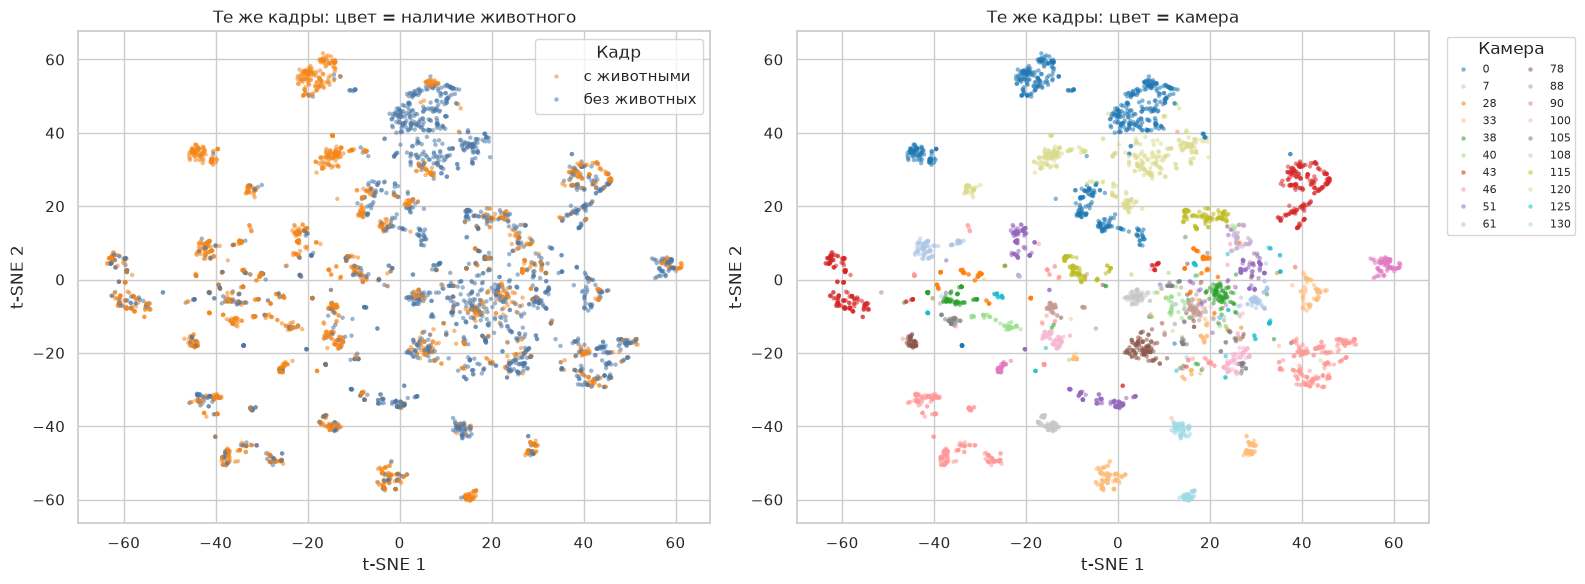

Численных признаков кадра: 880 | PCA объясняет: 0.678


In [20]:
with threadpool_limits(limits=2):
    image_pca = PCA(n_components=50, random_state=SEED, svd_solver='randomized')
    image_reduced = image_pca.fit_transform(image_vectors)
    image_xy = TSNE(n_components=2, perplexity=35, init='pca', learning_rate='auto',
                    max_iter=750, random_state=SEED, n_jobs=2).fit_transform(image_reduced)
image_projection = pd.DataFrame({'image_id': vector_ids, 'x': image_xy[:,0], 'y': image_xy[:,1]}).merge(
    images[['image_id', 'presence', 'location', 'split']], on='image_id', validate='one_to_one')
image_projection.to_parquet(TABLES/'caltech_projection.parquet', index=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=image_projection.sample(frac=1, random_state=SEED), x='x', y='y', hue='presence',
                palette=IMAGE_COLORS, s=10, alpha=.55, linewidth=0, ax=axes[0])
axes[0].set_title('Те же кадры: цвет = наличие животного')
axes[0].legend(title='Кадр')
location_palette = dict(zip(selected_cameras, sns.color_palette('tab20', n_colors=20)))
sns.scatterplot(data=image_projection.sample(frac=1, random_state=SEED), x='x', y='y', hue='location',
                hue_order=selected_cameras, palette=location_palette, s=10, alpha=.55, linewidth=0, ax=axes[1])
axes[1].set_title('Те же кадры: цвет = камера')
axes[1].legend(title='Камера', bbox_to_anchor=(1.02,1), loc='upper left', ncol=2, fontsize=8)
for ax in axes:
    ax.set(xlabel='t-SNE 1', ylabel='t-SNE 2')
finish('caltech_10_projection')
print('Численных признаков кадра:', image_vectors.shape[1], '| PCA объясняет:', round(image_pca.explained_variance_ratio_.sum(), 3))

На проекции видны группы кадров одних камер, при этом внутри многих групп
смешаны кадры с животными и без них. Для этих признаков заметно влияние фона
и режима съёмки; полного разделения по наличию животного нет.
Это поддерживает выбор независимых камер для train/val/test и необходимость
учить локализацию по рамкам, а не оценивать детектор только по общему виду сцены.

### 11. Выводы: какие камеры берём и сколько кадров

In [21]:
most_empty = (100*chosen_camera_table['доля_без_животных']).nlargest(3).round(1).to_dict()
mono_rates = (100*images.groupby('presence').is_monochrome.mean()).round(1).to_dict()
small_objects_percent = 100*box_stats.area_fraction.lt(.01).mean()
display(Markdown(
    f'Берём **{images.location.nunique()} камер**: '+', '.join(selected_cameras)+'. '
    f'Итого **{len(images):,} кадров**: **{int(images.has_animal.sum()):,} с животными** '
    f'и **{int((~images.has_animal).sum()):,} без животных**, **{len(box_stats):,} рамок animal**. '
    f'На камеру приходится **{int(camera_balance.sum(axis=1).min())}–{int(camera_balance.sum(axis=1).max())}** кадров. '
    f'Камеры с наибольшей долей кадров без животных до отбора: **{most_empty}**. '
    f'Доли почти ч/б в рабочей выборке: **{mono_rates}**. '
    f'Рамки меньше 1% площади кадра: **{small_objects_percent:.1f}%** всех рамок.'
))
show_table(camera_balance.join(images.groupby('location').split.first()), 'caltech_final_camera_selection')
display(Markdown("""
**Для обогащения:** сохранять и положительные, и отрицательные сцены, разнообразие
камер, освещения, размеров животных и положений в кадре. Отдельно полезны сложные
отрицательные примеры с людьми/машинами и маленькие/частично видимые животные.
Почти ч/б кадры встречаются среди положительных и отрицательных с разной частотой:
нужно дополнительно собирать ч/б отрицательные и цветные положительные примеры,
чтобы режим камеры не подменял признак присутствия животного.
Тёмные и размытые кадры не удалять без просмотра: это часть реальных условий съёмки.
На t-SNE учитывать влияние фона; проверить перенос на новые камеры можно только
независимым test по камерам и метриками детекции, а не картинкой точек.
При поворотах, масштабировании и обрезке пересчитывать все рамки.

Точные копии записаны в таблицу кандидатов; дубликатов между train/val/test нет.
Если удалять копии из рабочей выборки, нужно подобрать замену той же камеры
и того же типа кадра, чтобы сохранить 50/50 и фиксировать новую версию manifest.
Для детектора оценивать AP@0.50, mAP@0.50:0.95 и ложные срабатывания на кадрах
без животных; accuracy присутствия животного не оценивает правильность рамок.
"""))

Берём **20 камер**: 0, 7, 28, 33, 38, 40, 43, 46, 51, 61, 78, 88, 90, 100, 105, 108, 115, 120, 125, 130. Итого **4,000 кадров**: **2,000 с животными** и **2,000 без животных**, **2,068 рамок animal**. На камеру приходится **52–624** кадров. Камеры с наибольшей долей кадров без животных до отбора: **{'0': 62.2, '120': 50.1, '51': 22.2}**. Доли почти ч/б в рабочей выборке: **{'без животных': 25.6, 'с животными': 58.2}**. Рамки меньше 1% площади кадра: **10.3%** всех рамок.

,без животных,с животными,split
location,,,
0,312,312,val
7,77,77,test
28,62,62,test
33,129,129,train
38,78,78,train
40,43,43,val
43,191,191,train
46,246,246,test
51,126,126,train



**Для обогащения:** сохранять и положительные, и отрицательные сцены, разнообразие
камер, освещения, размеров животных и положений в кадре. Отдельно полезны сложные
отрицательные примеры с людьми/машинами и маленькие/частично видимые животные.
Почти ч/б кадры встречаются среди положительных и отрицательных с разной частотой:
нужно дополнительно собирать ч/б отрицательные и цветные положительные примеры,
чтобы режим камеры не подменял признак присутствия животного.
Тёмные и размытые кадры не удалять без просмотра: это часть реальных условий съёмки.
На t-SNE учитывать влияние фона; проверить перенос на новые камеры можно только
независимым test по камерам и метриками детекции, а не картинкой точек.
При поворотах, масштабировании и обрезке пересчитывать все рамки.

Точные копии записаны в таблицу кандидатов; дубликатов между train/val/test нет.
Если удалять копии из рабочей выборки, нужно подобрать замену той же камеры
и того же типа кадра, чтобы сохранить 50/50 и фиксировать новую версию manifest.
Для детектора оценивать AP@0.50, mAP@0.50:0.95 и ложные срабатывания на кадрах
без животных; accuracy присутствия животного не оценивает правильность рамок.


## Проверки результата

Файлы и сохранённые таблицы позволяют повторить анализ и проверить каждое число.
Текущие manifest, COCO/YOLO, split и исходные JPG при этом EDA не меняются.

In [22]:
assert len(text)==summary['telegram']['prepared_rows']
assert text[['label','text']].isna().sum().sum()==0
assert text.groupby('template_group').split.nunique().max()==1
assert len(images)==4000 and images.location.nunique()==20
assert images.groupby('split').has_animal.mean().eq(.5).all()
assert images.groupby('location').has_animal.mean().eq(.5).all()
assert images.groupby('location').split.nunique().max()==1
assert images.seq_id.is_unique and images.image_id.is_unique
assert images.groupby('sha256').split.nunique().max()==1
assert images.status.eq('ok').all() and images.dimensions_match.all()
assert coco['categories']==[{'id':1,'name':'animal'}]
assert len(box_stats)==images.n_boxes.sum()==len(coco['annotations'])
assert not box_stats.invalid.any() and box_stats.category_id.eq(1).all()
assert images.loc[~images.has_animal,'n_boxes'].eq(0).all()
assert images.loc[images.has_animal,'n_boxes'].ge(1).all()
assert np.isfinite(text_xy).all() and np.isfinite(image_xy).all()
assert len(image_projection)==len(images)
assert text_projection.sample_id.is_unique
print('Все проверки пройдены. Графики:', FIGURES, '| таблицы и координаты:', TABLES)

Все проверки пройдены. Графики: /home/katya/2курс/DS/data-enrichment-study/artifacts/figures | таблицы и координаты: /home/katya/2курс/DS/data-enrichment-study/artifacts/tables
